## Summative Lab: Forest Fires Prevention

### Step 1: Load the Dataset

*   Install and import the ucimlrepo library.
*   Load the Forest Fires dataset:
 *   Predictors: Features from forest_fires.data.features.
 *   Target: forest_fires.data.targets.

In [19]:
# Run pip install if necessary to access the UCI ML Repository (uncomment the next line)
! pip install ucimlrepo
! pip install scikit-learn


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
# Data
from ucimlrepo import fetch_ucirepo


forest_fires = fetch_ucirepo(id=162)
X = forest_fires.data.features
y = forest_fires.data.targets


# Display dataset structure
print(X.info())
print(X.describe())
print(y.head())

<class 'pandas.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       517 non-null    int64  
 1   Y       517 non-null    int64  
 2   month   517 non-null    str    
 3   day     517 non-null    str    
 4   FFMC    517 non-null    float64
 5   DMC     517 non-null    float64
 6   DC      517 non-null    float64
 7   ISI     517 non-null    float64
 8   temp    517 non-null    float64
 9   RH      517 non-null    int64  
 10  wind    517 non-null    float64
 11  rain    517 non-null    float64
dtypes: float64(7), int64(3), str(2)
memory usage: 48.6 KB
None
                X           Y        FFMC         DMC          DC         ISI  \
count  517.000000  517.000000  517.000000  517.000000  517.000000  517.000000   
mean     4.669246    4.299807   90.644681  110.872340  547.940039    9.021663   
std      2.313778    1.229900    5.520111   64.046482  248.066192    4.559477   


### Step 2: EDA

* Examine the dataset structure and summary statistics.
* Analyze correlations between predictors and the target variable.
* Plot scatterplots for key predictors vs. the target.
* Generate a residual plot to check for randomness in residuals.

(517, 14)
X             int64
Y             int64
month           str
day             str
FFMC        float64
DMC         float64
DC          float64
ISI         float64
temp        float64
RH            int64
wind        float64
rain        float64
area        float64
log_area    float64
dtype: object
Missing values: 0
          count        mean         std   min    25%        50%         75%  \
X         517.0    4.669246    2.313778   1.0    3.0    4.00000    7.000000   
Y         517.0    4.299807    1.229900   2.0    4.0    4.00000    5.000000   
FFMC      517.0   90.644681    5.520111  18.7   90.2   91.60000   92.900000   
DMC       517.0  110.872340   64.046482   1.1   68.6  108.30000  142.400000   
DC        517.0  547.940039  248.066192   7.9  437.7  664.20000  713.900000   
ISI       517.0    9.021663    4.559477   0.0    6.5    8.40000   10.800000   
temp      517.0   18.889168    5.806625   2.2   15.5   19.30000   22.800000   
RH        517.0   44.288201   16.317469  15.0 

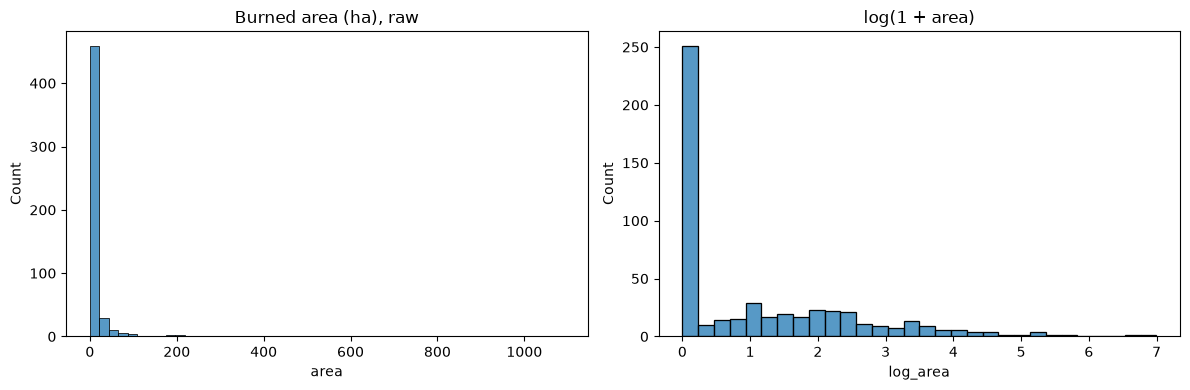

          area  log_area
DMC   0.072994  0.067153
wind  0.012317  0.066973
DC    0.049383  0.066360
X     0.063385  0.061995
RH   -0.075519 -0.053662
temp  0.097844  0.053487
FFMC  0.040122  0.046799
Y     0.044873  0.038838
rain -0.007366  0.023311
ISI   0.008258 -0.010347


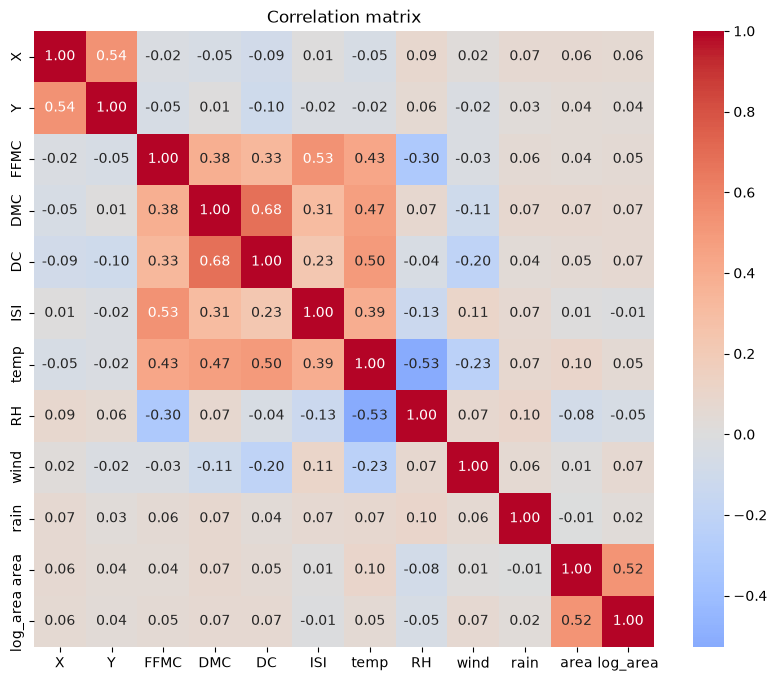

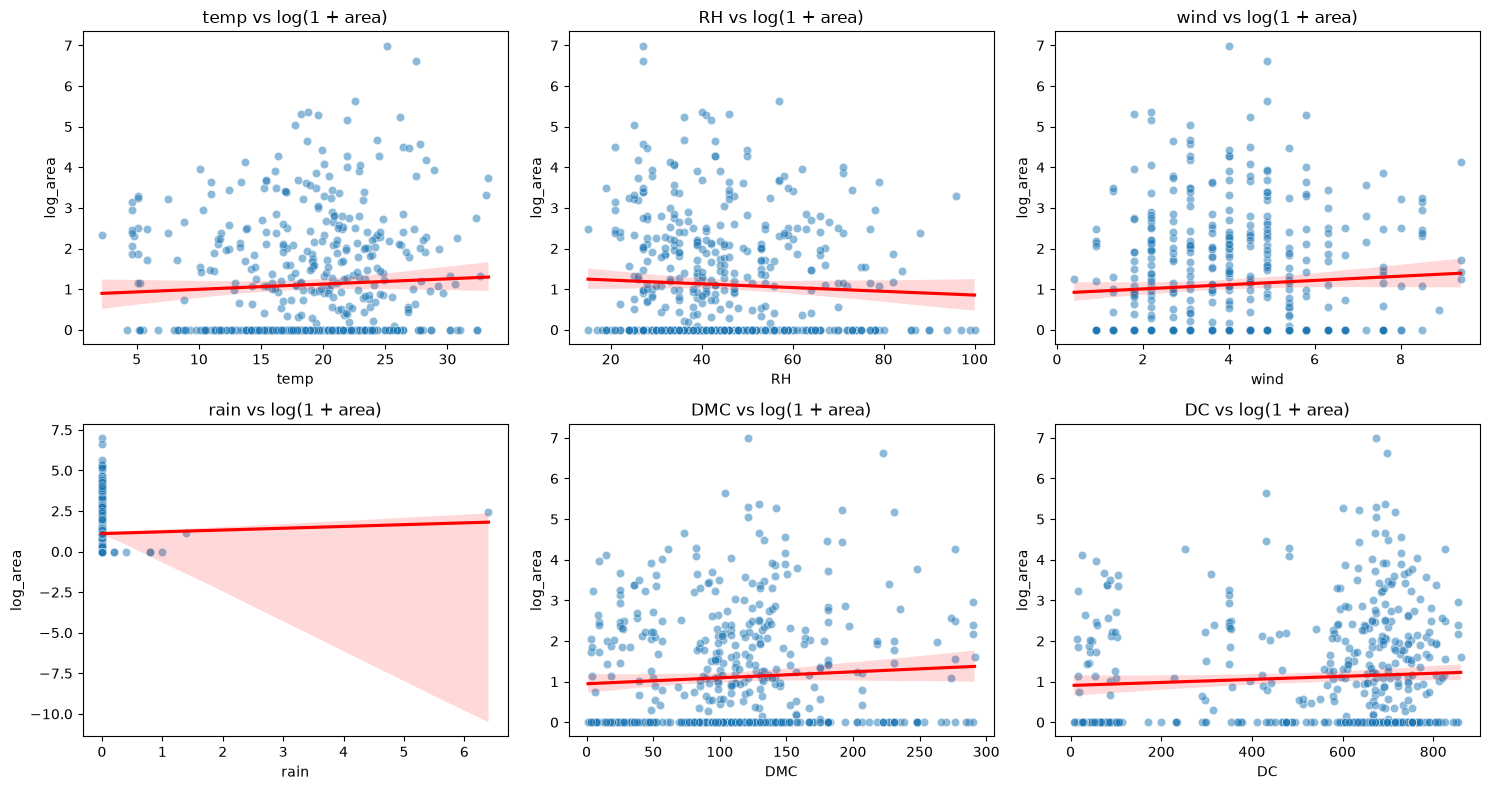

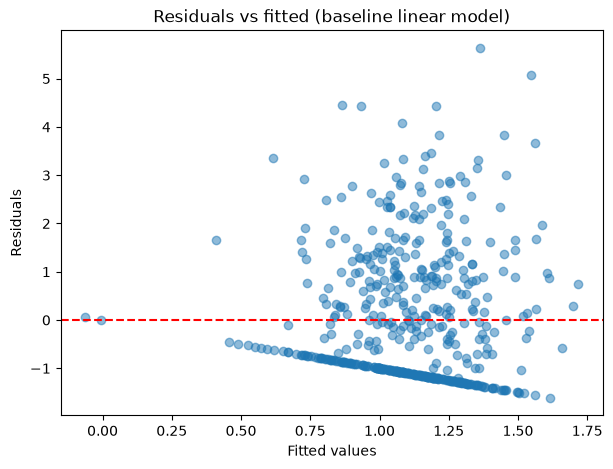

Baseline R²: 0.025


In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

# Combine predictors and target for EDA
data = X.copy()
data["area"] = y["area"]
data["log_area"] = np.log1p(data["area"])


print(data.shape)
print(data.dtypes)
print("Missing values:", data.isna().sum().sum())
print(data.describe().T)
#
#raw vs log
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data["area"], bins=50, ax=axes[0])
axes[0].set_title("Burned area (ha), raw")
sns.histplot(data["log_area"], bins=30, ax=axes[1])
axes[1].set_title("log(1 + area)")
plt.tight_layout()
plt.show()

#correlations
num_cols = X.select_dtypes(include="number").columns.tolist()

corr = data[num_cols + ["area", "log_area"]].corr()

print(corr[["area", "log_area"]].drop(["area", "log_area"]).sort_values("log_area", key=abs, ascending=False))

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

#predicator vs target 
key_predictors = ["temp", "RH", "wind", "rain", "DMC", "DC"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), key_predictors):
    sns.scatterplot(x=data[col], y=data["log_area"], alpha=0.5, ax=ax)
    sns.regplot(x=data[col], y=data["log_area"], scatter=False, color="red", ax=ax)
    ax.set_title(f"{col} vs log(1 + area)")
plt.tight_layout()
plt.show()

#residual plot
Xn = data[num_cols]
yl = data["log_area"]

baseline = LinearRegression().fit(Xn, yl)
fitted = baseline.predict(Xn)
residuals = yl - fitted

plt.figure(figsize=(7, 5))
plt.scatter(fitted, residuals, alpha=0.5)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs fitted (baseline linear model)")
plt.show()

print("Baseline R²:", round(baseline.score(Xn, yl), 3))

### Step 3: Fit the regression models

* Fit a baseline multiple linear regression model with key predictors.
* Include nonlinear terms (e.g., quadratic transformations for significant predictors).
* Add interaction terms (e.g., between predictors with strong correlations).
* Incorporate indicator variables if categorical variables are present.
* Apply transformations (e.g., logarithmic transformations for skewed predictors).

In [22]:
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, KFold

target = "log_area"
results = []   

def fit_model(X_model, name):
    """Fit OLS on log_area, store fit statistics, and return the statsmodels result."""
    X_model = X_model.astype(float)
    ols = sm.OLS(data[target], sm.add_constant(X_model)).fit()
    cv_r2 = cross_val_score(
        LinearRegression(), X_model, data[target],
        cv=KFold(5, shuffle=True, random_state=42), scoring="r2"
    ).mean()
    results.append({
        "model": name, "n_predictors": X_model.shape[1],
        "R2": ols.rsquared, "adj_R2": ols.rsquared_adj,
        "AIC": ols.aic, "BIC": ols.bic, "CV_R2": cv_r2
    })
    return ols

#Baseline model with all predictors
key_predictors = ["temp", "RH", "wind", "rain", "DMC", "DC"]

m_base = fit_model(data[key_predictors], "Baseline")
print(m_base.summary())

#nonlinear terms
X_quad = data[key_predictors].copy()
for col in ["temp", "RH", "wind", "DMC"]:
    X_quad[f"{col}_sq"] = (data[col] - data[col].mean()) ** 2

m_quad = fit_model(X_quad, "Quadratic")
print(m_quad.summary().tables[1])

#interaction terms
X_int = data[key_predictors].copy()
for col in ["temp", "RH", "wind", "DMC", "DC"]:
    X_int[col] = data[col] - data[col].mean()

X_int["temp_x_RH"]   = X_int["temp"] * X_int["RH"]
X_int["DMC_x_DC"]    = X_int["DMC"] * X_int["DC"]
X_int["temp_x_wind"] = X_int["temp"] * X_int["wind"]

m_int = fit_model(X_int, "Interactions")
print(m_int.summary().tables[1])

# Month only
month_dummies = pd.get_dummies(data["month"], prefix="month", drop_first=True)
m_month = fit_model(pd.concat([data[key_predictors], month_dummies], axis=1), "Baseline + month")

# Month and day of week
cat_dummies = pd.get_dummies(data[["month", "day"]], drop_first=True)
m_cat = fit_model(pd.concat([data[key_predictors], cat_dummies], axis=1), "Baseline + month + day")

#transformations
print(data[["ISI", "rain", "FFMC", "DMC", "DC", "wind", "temp", "RH"]].skew().round(2))

X_log = data[key_predictors].copy()
X_log["rain"] = np.log1p(data["rain"])
X_log["DMC"]  = np.log1p(data["DMC"])
X_log["ISI"]  = np.log1p(data["ISI"])

m_log = fit_model(X_log, "Log-transformed")

X_combo = pd.concat([X_quad, X_int[["temp_x_RH", "DMC_x_DC"]]], axis=1)
X_combo["rain"] = np.log1p(data["rain"])

m_combo = fit_model(X_combo, "Quadratic + interactions + log(rain)")

comparison = pd.DataFrame(results).set_index("model").round(3)
comparison

                            OLS Regression Results                            
Dep. Variable:               log_area   R-squared:                       0.016
Model:                            OLS   Adj. R-squared:                  0.004
Method:                 Least Squares   F-statistic:                     1.382
Date:                Fri, 20 Nov 2026   Prob (F-statistic):              0.220
Time:                        18:24:14   Log-Likelihood:                -902.30
No. Observations:                 517   AIC:                             1819.
Df Residuals:                     510   BIC:                             1848.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.9202      0.468      1.967      0.0

,n_predictors,R2,adj_R2,AIC,BIC,CV_R2
model,,,,,,
Baseline,6,0.016,0.004,1818.599,1848.335,-0.055
Quadratic,10,0.039,0.020,1814.159,1860.887,-0.028
Interactions,9,0.026,0.009,1819.345,1861.826,-0.051
Baseline + month,17,0.061,0.029,1816.276,1892.741,-0.057
Baseline + month + day,23,0.067,0.024,1824.905,1926.858,-0.072
Log-transformed,7,0.017,0.003,1820.085,1854.069,-0.027
Quadratic + interactions + log(rain),12,0.043,0.020,1816.151,1871.376,-0.009


### Step 4: Evaluate model diagnostics

* Compare models using metrics like 2R^2, adjusted RR^2, AIC, and BIC.
* Plot residuals and create Q-Q plots to assess normality.
* Identify influential observations using Cook's Distance.

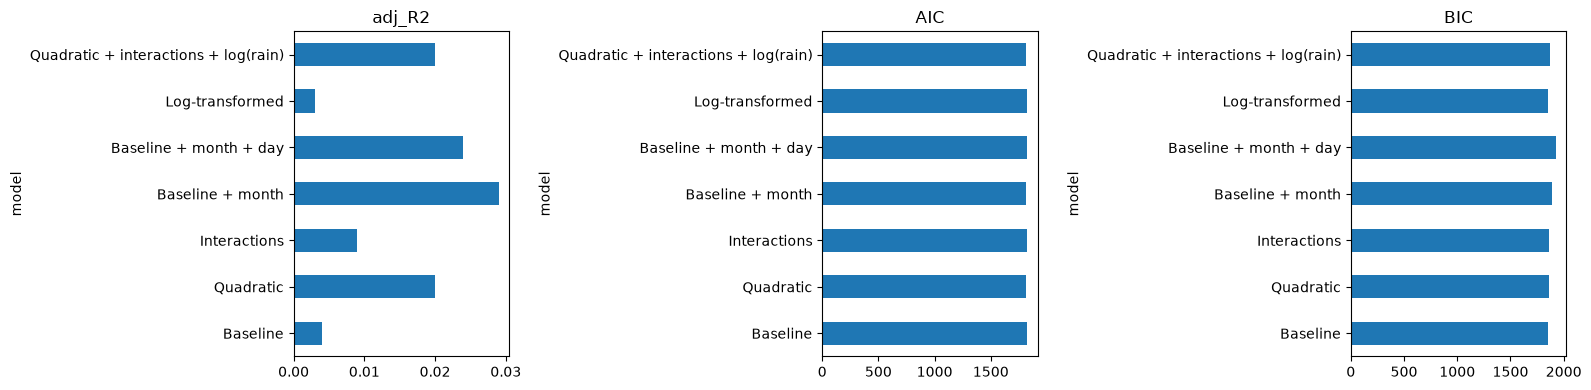

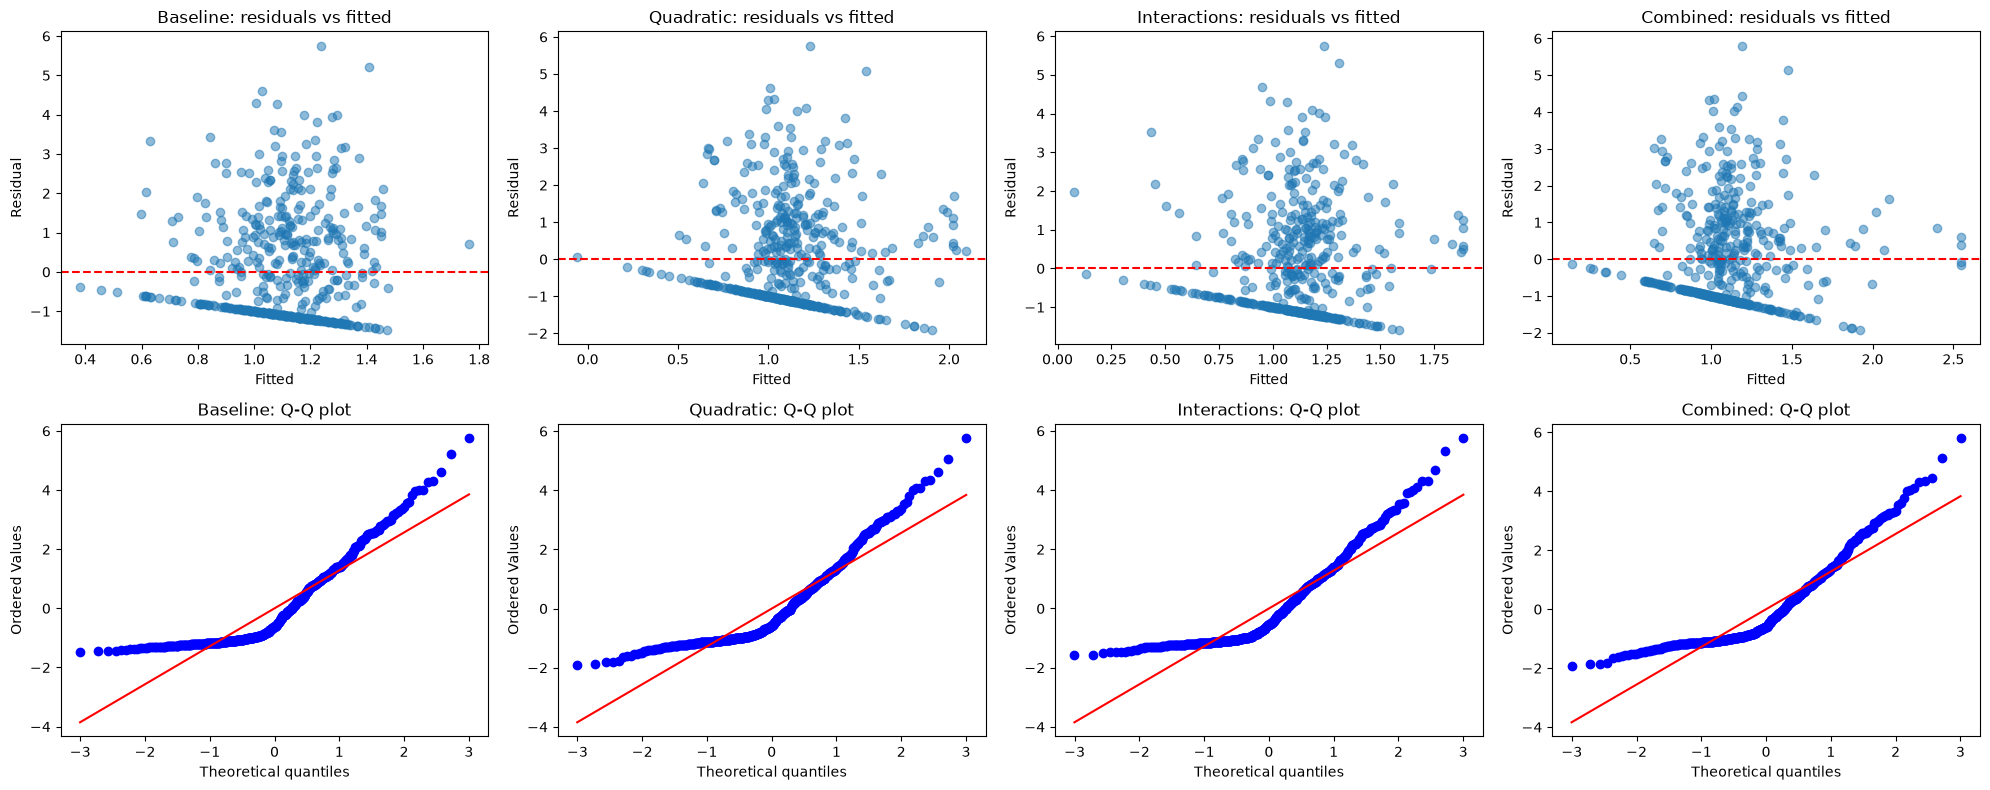

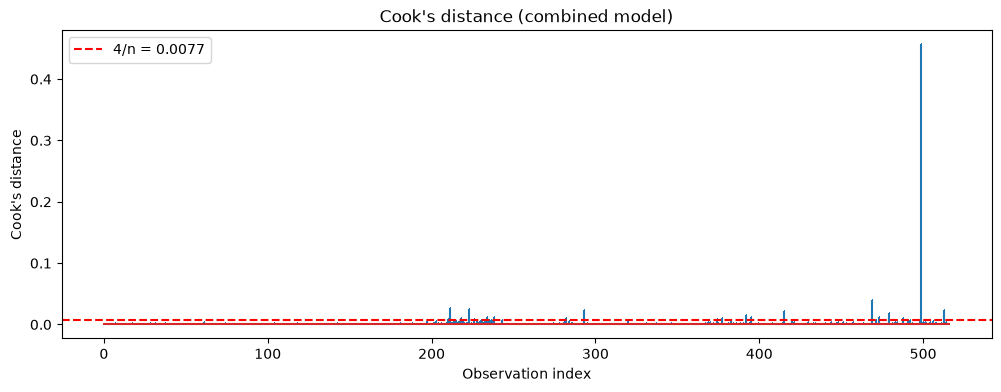

Observations above 4/n: 21
      area  temp  RH  wind    DMC     DC month   cooks_d
499  10.82  27.3  63   4.9  181.1  671.2   aug  0.456360
469  61.13  13.7  33   9.4   14.6   25.6   apr  0.040674
211  26.00   5.1  96   5.8  139.4  594.2   aug  0.027308
223  37.02  13.4  79   3.6  150.3  309.9   jul  0.025523
513  54.29  21.9  71   5.8   56.7  665.6   aug  0.024325
R²  with all points: 0.043   without obs 499: 0.047
Adj R² with all: 0.020   without: 0.024


In [23]:
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
import scipy.stats as stats

comparison.sort_values("AIC")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ["adj_R2", "AIC", "BIC"]):
    comparison[metric].plot(kind="barh", ax=ax)
    ax.set_title(metric)
plt.tight_layout()
plt.show()

diag_models = {
    "Baseline": m_base,
    "Quadratic": m_quad,
    "Interactions": m_int,
    "Combined": m_combo,
}

#residual plots and Q-Q plots
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for i, (name, model) in enumerate(diag_models.items()):
    # Residuals vs fitted
    axes[0, i].scatter(model.fittedvalues, model.resid, alpha=0.5)
    axes[0, i].axhline(0, color="red", linestyle="--")
    axes[0, i].set_title(f"{name}: residuals vs fitted")
    axes[0, i].set_xlabel("Fitted")
    axes[0, i].set_ylabel("Residual")

    # Q-Q plot
    stats.probplot(model.resid, dist="norm", plot=axes[1, i])
    axes[1, i].set_title(f"{name}: Q-Q plot")
plt.tight_layout()
plt.show()

rows = []
for name, model in diag_models.items():
    bp_p = het_breuschpagan(model.resid, model.model.exog)[1]
    sw_p = stats.shapiro(model.resid)[1]
    rows.append({
        "model": name,
        "Breusch-Pagan p": bp_p,
        "Shapiro-Wilk p": sw_p,
        "Durbin-Watson": durbin_watson(model.resid),
        "resid skew": model.resid.skew(),
    })
pd.DataFrame(rows).set_index("model").round(4)

influence = m_combo.get_influence()
cooks_d = influence.cooks_distance[0]
n = len(cooks_d)
threshold = 4 / n

plt.figure(figsize=(12, 4))
plt.stem(np.arange(n), cooks_d, markerfmt=",")
plt.axhline(threshold, color="red", linestyle="--", label=f"4/n = {threshold:.4f}")
plt.xlabel("Observation index")
plt.ylabel("Cook's distance")
plt.title("Cook's distance (combined model)")
plt.legend()
plt.show()

print("Observations above 4/n:", (cooks_d > threshold).sum())

# Top 5 most influential observations
top = np.argsort(cooks_d)[-5:][::-1]
display_cols = ["area", "temp", "RH", "wind", "DMC", "DC", "month"]
print(data.loc[top, display_cols].assign(cooks_d=cooks_d[top]))

worst = top[0]
keep = data.index != data.index[worst]

ols_wo = sm.OLS(data.loc[keep, target], sm.add_constant(X_combo.loc[keep].astype(float))).fit()
print(f"R²  with all points: {m_combo.rsquared:.3f}   without obs {worst}: {ols_wo.rsquared:.3f}")
print(f"Adj R² with all: {m_combo.rsquared_adj:.3f}   without: {ols_wo.rsquared_adj:.3f}")

### Step 5: Apply regularization

* Use Ridge (L2) and Lasso (L1) regression from sklearn to handle multicollinearity.
* Extract coefficients and calculate Mean Squared Error (MSE).
* Compare the performance of Ridge and Lasso models.

(517, 27) (413, 27) (104, 27)
Best Ridge alpha: 1000.000
Best Lasso alpha: 0.0910
Lasso kept 5 of 27 features


,OLS,Ridge,Lasso
X,0.128,0.031,0.021
Y,-0.005,0.017,0.000
FFMC,0.105,0.019,0.000
DMC,0.323,0.035,0.054
DC,-0.469,0.015,0.000
ISI,-0.077,-0.008,-0.000
temp,0.164,0.012,0.000
RH,0.039,-0.008,-0.000
wind,0.051,0.014,0.000
rain,0.016,0.011,0.000



Features kept by Lasso:


,OLS,Ridge,Lasso
X,0.128,0.031,0.021
DMC,0.323,0.035,0.054
month_dec,0.328,0.055,0.102
month_may,0.152,0.039,0.041
month_sep,0.623,0.028,0.027


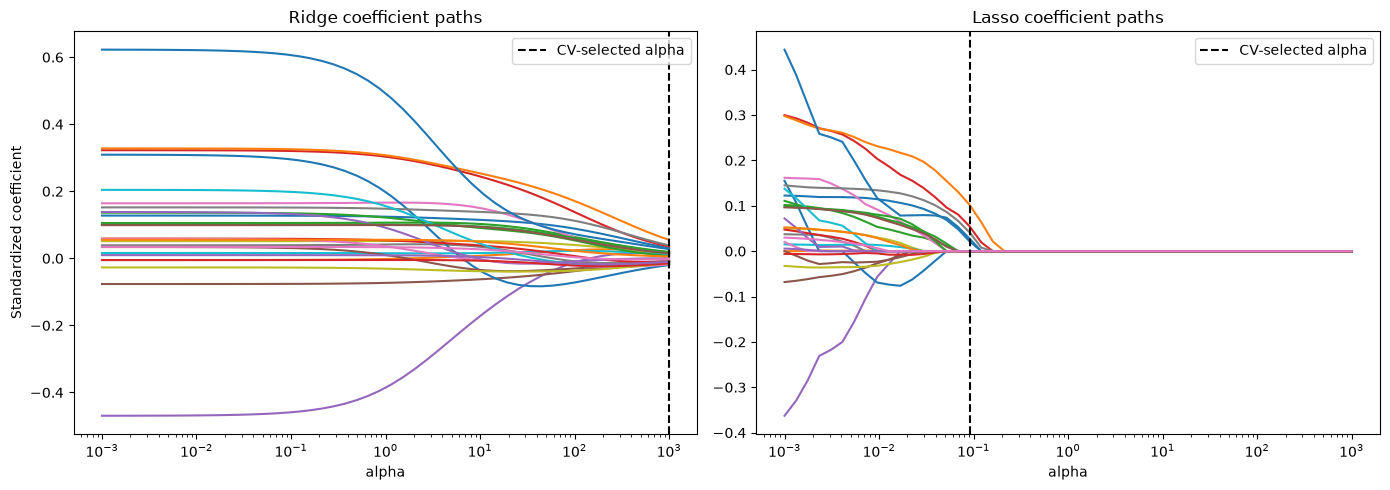

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV, lasso_path
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor


num_cols = X.select_dtypes(include="number").columns.tolist()
cat_dummies = pd.get_dummies(data[["month", "day"]], drop_first=True).astype(float)
X_reg = pd.concat([data[num_cols], cat_dummies], axis=1)
y_reg = data["log_area"]

X_train, X_test, y_train, y_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)


scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

print(X_reg.shape, X_train.shape, X_test.shape)

#fit ridge and lasso models
alphas = np.logspace(-3, 3, 50)

ols   = LinearRegression().fit(X_train_s, y_train)
ridge = RidgeCV(alphas=alphas, cv=5, scoring="neg_mean_squared_error").fit(X_train_s, y_train)
lasso = LassoCV(alphas=alphas, cv=5, random_state=42, max_iter=10000).fit(X_train_s, y_train)
mean_model = DummyRegressor(strategy="mean").fit(X_train_s, y_train)

print(f"Best Ridge alpha: {ridge.alpha_:.3f}")
print(f"Best Lasso alpha: {lasso.alpha_:.4f}")
print(f"Lasso kept {(lasso.coef_ != 0).sum()} of {len(lasso.coef_)} features")

#extract coefficients
coef_table = pd.DataFrame({"OLS": ols.coef_, "Ridge": ridge.coef_, "Lasso": lasso.coef_},index=X_reg.columns)
display(coef_table.round(3))

print("\nFeatures kept by Lasso:")
display(coef_table.loc[coef_table["Lasso"] != 0].round(3))

#Comparison
models = {"Mean predictor": mean_model, "OLS": ols, "Ridge": ridge, "Lasso": lasso}

rows = []
for name, m in models.items():
    rows.append({
        "model": name,
        "train MSE": mean_squared_error(y_train, m.predict(X_train_s)),
        "test MSE": mean_squared_error(y_test, m.predict(X_test_s)),
        "test R²": r2_score(y_test, m.predict(X_test_s)),
    })
mse_table = pd.DataFrame(rows).set_index("model").round(4)
mse_table


# Lasso path
alphas_l, coefs_l, _ = lasso_path(X_train_s, y_train, alphas=alphas)

# Ridge path
coefs_r = np.array([Ridge(alpha=a).fit(X_train_s, y_train).coef_ for a in alphas])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(alphas, coefs_r)
axes[0].set_xscale("log")
axes[0].set_title("Ridge coefficient paths")
axes[0].set_xlabel("alpha")
axes[0].set_ylabel("Standardized coefficient")

axes[1].plot(alphas_l, coefs_l.T)
axes[1].set_xscale("log")
axes[1].set_title("Lasso coefficient paths")
axes[1].set_xlabel("alpha")

for ax, a in zip(axes, [ridge.alpha_, lasso.alpha_]):
    ax.axvline(a, color="black", linestyle="--", label="CV-selected alpha")
    ax.legend()
plt.tight_layout()
plt.show()

### Step 6: Prepare the data for binary classification

* Create a binary target variable based on a threshold in y (e.g., median or other percentile).
* Select relevant predictors and scale them using StandardScaler.

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Threshold: median burned area
threshold = data["area"].median()
print(f"Median area (threshold): {threshold} ha")

# 1 = "high-risk" fire, 0 = otherwise
data["high_risk"] = (data["area"] > threshold).astype(int)

print(data["high_risk"].value_counts())
print(data["high_risk"].value_counts(normalize=True).round(3))

#Numeric predictors only
clf_features = X.select_dtypes(include="number").columns.tolist()
X_clf = data[clf_features]
y_clf = data["high_risk"]


X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

scaler_c = StandardScaler().fit(X_train_c)
X_train_cs = scaler_c.transform(X_train_c)
X_test_cs = scaler_c.transform(X_test_c)

print("Train:", X_train_cs.shape, " Test:", X_test_cs.shape)
print("Train class balance:", y_train_c.mean().round(3), " Test class balance:", y_test_c.mean().round(3))
data.groupby("high_risk")[clf_features].mean().round(2).T

Median area (threshold): 0.52 ha
high_risk
0    259
1    258
Name: count, dtype: int64
high_risk
0    0.501
1    0.499
Name: proportion, dtype: float64
Train: (413, 10)  Test: (104, 10)
Train class balance: 0.499  Test class balance: 0.5


high_risk,0,1
X,4.54,4.80
Y,4.24,4.36
FFMC,90.26,91.04
DMC,107.44,114.32
DC,529.27,566.69
ISI,8.93,9.11
temp,18.52,19.26
RH,45.00,43.57
wind,3.89,4.14
rain,0.01,0.03


### Step 7: Train and evaluate a logistic regression model

Train a logistic regression model using the scaled predictors.

* Display coefficients and the intercept.
* Predict probabilities and binary outcomes.
* Evaluate performance using accuracy, confusion matrix, precision, recall, and F1-score.

Intercept: [-0.008]
Accuracy : 0.500
Precision: 0.500
Recall   : 0.481
F1-score : 0.490
ROC AUC  : 0.535
Train accuracy: 0.530

Confusion matrix:
[[27 25]
 [27 25]]

               precision    recall  f1-score   support

           0       0.50      0.52      0.51        52
           1       0.50      0.48      0.49        52

    accuracy                           0.50       104
   macro avg       0.50      0.50      0.50       104
weighted avg       0.50      0.50      0.50       104



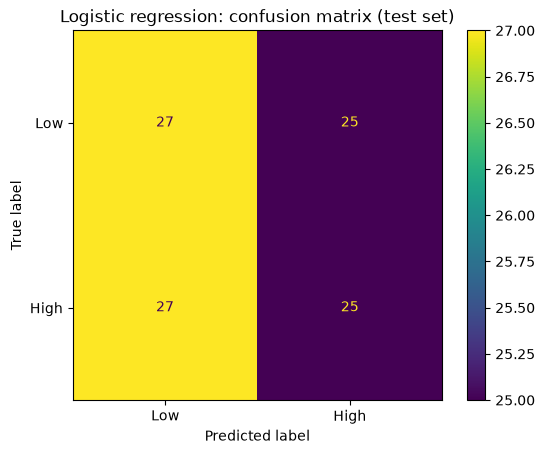

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score, recall_score, f1_score, classification_report, roc_auc_score, ConfusionMatrixDisplay)

logit = LogisticRegression(max_iter=1000, random_state=42)
logit.fit(X_train_cs, y_train_c)

print("Intercept:", logit.intercept_.round(3))

coef_df = pd.DataFrame({
    "feature": clf_features,
    "coefficient": logit.coef_[0],
    "odds_ratio": np.exp(logit.coef_[0]),
}).sort_values("coefficient", key=abs, ascending=False).set_index("feature")

coef_df.round(3)

y_prob = logit.predict_proba(X_test_cs)[:, 1]
y_pred = logit.predict(X_test_cs)

pd.DataFrame({
    "actual": y_test_c.values[:10],
    "prob_high_risk": y_prob[:10].round(3),
    "predicted": y_pred[:10],
})

y_prob = logit.predict_proba(X_test_cs)[:, 1]
y_pred = logit.predict(X_test_cs)

pd.DataFrame({
    "actual": y_test_c.values[:10],
    "prob_high_risk": y_prob[:10].round(3),
    "predicted": y_pred[:10],
})

#evaluate metrics
print(f"Accuracy : {accuracy_score(y_test_c, y_pred):.3f}")
print(f"Precision: {precision_score(y_test_c, y_pred):.3f}")
print(f"Recall   : {recall_score(y_test_c, y_pred):.3f}")
print(f"F1-score : {f1_score(y_test_c, y_pred):.3f}")
print(f"ROC AUC  : {roc_auc_score(y_test_c, y_prob):.3f}")
print(f"Train accuracy: {logit.score(X_train_cs, y_train_c):.3f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_test_c, y_pred))

print("\n", classification_report(y_test_c, y_pred))

ConfusionMatrixDisplay.from_predictions(y_test_c, y_pred, display_labels=["Low", "High"])
plt.title("Logistic regression: confusion matrix (test set)")
plt.show()

### Step 8: Check assumptions

* Use Variance Inflation Factor (VIF) to assess multicollinearity among predictors.

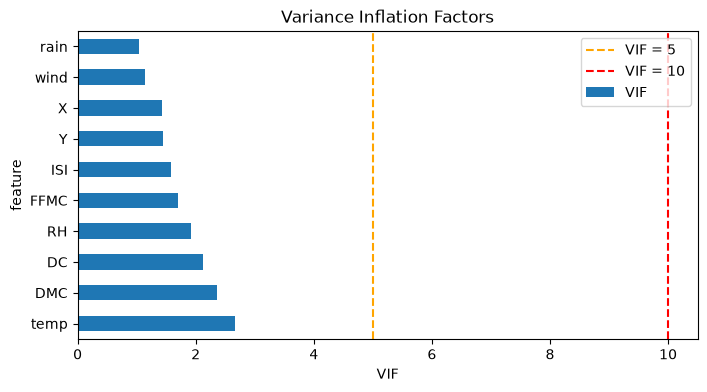

In [27]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = sm.add_constant(X_clf)

vif_table = pd.DataFrame({
    "feature": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
vif_table = vif_table[vif_table["feature"] != "const"].sort_values("VIF", ascending=False).set_index("feature")
vif_table.round(2)

#bar chart
plt.figure(figsize=(8, 4))
vif_table["VIF"].plot(kind="barh")
plt.axvline(5, color="orange", linestyle="--", label="VIF = 5")
plt.axvline(10, color="red", linestyle="--", label="VIF = 10")
plt.xlabel("VIF")
plt.title("Variance Inflation Factors")
plt.legend()
plt.show()

### Step 9: Summative Findings

* Compare regression models and classification results.
* Highlight trade-offs between model simplicity, performance, and interpretability.
* Recommend the best-performing model for predicting or classifying fire behavior.

Summative Findings:
1. Compare regression models and classification results.
-Neither approach worked well. The regression models explained almost none of the variation in burned area (R² of 0.07 at best), and the logistic regression classifier was right only about 50% of the time. Both point to the same conclusion: the weather and fire-index variables in this dataset don't tell us much about how big a fire will be.


2. Highlight trade-offs between model simplicity, performance, and interpretability.
-Making the regression models more complex (adding quadratic terms, interactions and month/day indicators) made them fit the training data better but predict new data worse, so the extra complexity wasn't worth it. Regularization gave the best balance, because Lasso performed as well as Ridge while keeping only 5 of 27 features, which makes it much easier to explain. The logistic regression is easy to interpret, but all of its effects are weak.


3. Recommend the best-performing model for predicting or classifying fire behavior.
-Of the models we tested, I'd recommend the Lasso regression, since it had the lowest test error (tied with Ridge) and the simplest form. That said, it only beats simply predicting the average by a tiny margin, so none of these models is reliable enough to decide where to send resources. To improve on this, we would need better data, such as elevation, vegetation and distance to urban areas.